# AQI Data Exploration
Inspect the CSV, understand missing inputs and category support, and check station-separated partitions.
This notebook does **not** train classifiers, fit preprocessing, or save models.
Run `python train.py` separately when you are ready.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

working = Path.cwd().resolve()
ROOT = next((p for p in (working, *working.parents)
             if (p / "data_preprocessing.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the extracted AQI_Project_Simple folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from data_preprocessing import DATA_PATH, FEATURES, POLLUTANTS, CLASSES
from data_preprocessing import load_data, split_data

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 25)


## 1. Original dataset
Put your existing `waqi_global_dataset_with_categoricals.csv` inside `data/`.
WAQI `iaqi` pollutant fields are individual AQI subindices, not raw pollutant concentrations.
The model estimates the current category; these snapshots do not support future forecasting.


In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Copy your dataset to: {DATA_PATH}")
raw = pd.read_csv(DATA_PATH)
print("Original rows and columns:", raw.shape)
display(raw.head())
display(pd.DataFrame({"dtype": raw.dtypes.astype(str),
                      "missing": raw.isna().sum(),
                      "missing_percent": raw.isna().mean().mul(100).round(2)}))


Original rows and columns: (12815, 20)


,uid,time,aqi,city_name,lat,lon,pm25,pm10,no2,so2,co,o3,temp_c,humidity_pct,pressure_hpa,wind_speed_mps,aqi_category,month,season,temp_condition
0,428,2025-09-21 01:00:00,107.0,"Osorno, Chile",-40.584479,-73.118720,107.0,37.0,NaN,NaN,NaN,NaN,8.7,93.8,1008.3,0.9,Unhealthy for Sensitive,9,Autumn,Cold
1,8821,2025-09-21 01:00:00,63.0,"Mirasol, Chile",-41.479507,-72.968756,63.0,NaN,NaN,NaN,NaN,NaN,8.0,93.0,1013.0,1.0,Moderate,9,Autumn,Cold
2,14756,2025-09-21 02:00:00,46.0,"Puerto Varas, Chile",-41.328935,-72.968209,46.0,12.0,NaN,NaN,NaN,NaN,8.0,93.0,1013.0,1.0,Good,9,Autumn,Cold
3,445,2025-09-21 02:00:00,152.0,"Coyhaique, Chile",-45.579964,-72.061126,152.0,46.0,NaN,NaN,NaN,NaN,6.0,87.0,1008.0,7.2,Unhealthy,9,Autumn,Cold
4,10699,2025-09-21 01:00:00,38.0,"Vialidad, Chile",-45.406800,-72.696260,38.0,NaN,NaN,NaN,NaN,NaN,6.0,93.0,1009.0,8.2,Good,9,Autumn,Cold


,dtype,missing,missing_percent
uid,int64,0,0.00
time,object,0,0.00
aqi,float64,114,0.89
city_name,object,0,0.00
lat,float64,0,0.00
lon,float64,0,0.00
pm25,float64,1295,10.11
pm10,float64,2155,16.82
no2,float64,2862,22.33
so2,float64,4617,36.03


## 2. Preparation audit
Invalid input cells become missing. Rows without a valid target or any input pollutant are excluded.
Extreme valid pollutant values and negative latitude/longitude values are retained.
`aqi` defines the target and never enters the model inputs.


In [3]:
data, audit = load_data(DATA_PATH)
display(pd.Series(audit, name="Count").to_frame())
print("Model inputs:", FEATURES)
display(data.head())
display(data[FEATURES].describe().T)


,Count
source_rows,12815
duplicates_removed,0
missing_target_rows,114
labeled_rows_without_input_pollutants,98
eligible_rows,12603
stations,4527


Model inputs: ['pm25', 'pm10', 'lon', 'lat', 'no2', 'co', 'temp_c']


,pm25,pm10,lon,lat,no2,co,temp_c,target,uid,source_row
0,107.0,37.0,-73.118720,-40.584479,NaN,NaN,8.7,Unhealthy for Sensitive Groups,428,0
1,63.0,NaN,-72.968756,-41.479507,NaN,NaN,8.0,Moderate,8821,1
2,46.0,12.0,-72.968209,-41.328935,NaN,NaN,8.0,Good,14756,2
3,152.0,46.0,-72.061126,-45.579964,NaN,NaN,6.0,Unhealthy,445,3
4,38.0,NaN,-72.696260,-45.406800,NaN,NaN,6.0,Good,10699,4


,count,mean,std,min,25%,50%,75%,max
pm25,11468.0,34.875183,32.332738,1.000000,15.000000,25.000000,48.000000,832.000000
pm10,10595.0,19.491166,43.533632,1.000000,8.000000,13.000000,22.000000,2138.000000
lon,12603.0,32.429548,84.428992,-161.767000,-5.531620,21.157309,115.013667,176.919127
lat,12603.0,34.299501,20.408152,-53.158295,31.352859,38.451900,46.577600,69.656250
no2,9860.0,5.809145,6.690020,0.100000,1.900000,3.800000,7.400000,124.000000
co,6563.0,3.590168,12.100150,0.100000,0.900000,2.600000,4.600000,500.000000
temp_c,12185.0,19.290339,7.586150,-67.700000,14.000000,19.400000,25.000000,63.700000


## 3. Stations and observation times
Multiple rows from the same station must stay in one partition.
Check the time coverage before making claims about forecasting or long-term behavior.


In [4]:
station_sizes = data.groupby("uid").size()
display(station_sizes.value_counts().sort_index().rename_axis("Rows per station").to_frame("Stations"))
if "time" in raw:
    observed_times = pd.to_datetime(raw["time"], errors="coerce", utc=True)
    print("First recorded time:", observed_times.min())
    print("Last recorded time:", observed_times.max())
    print("Unparseable/missing times:", observed_times.isna().sum())


,Stations
Rows per station,
1,79
2,820
3,3628


First recorded time: 2022-01-05 16:00:00+00:00
Last recorded time: 2025-09-23 02:00:00+00:00
Unparseable/missing times: 0


## 4. Station-separated partitions
Approximately 60% training, 20% validation and 20% testing. A fixed, label-based repair moves whole
stations into training when a rare observed category would otherwise be missing there.
No prediction scores are used for this repair. Sparse categories can remain unreliable.
The support table is a data audit; later modeling plots below use training rows only.


In [5]:
splits = split_data(data, seed=42)
groups = {name: set(data.iloc[positions]["uid"]) for name, positions in splits.items()}
assert not groups["train"] & groups["validation"]
assert not groups["train"] & groups["test"]
assert not groups["validation"] & groups["test"]
display(pd.DataFrame({name: {"rows": len(positions), "stations": len(groups[name])}
                      for name, positions in splits.items()}).T)
support = pd.DataFrame({name: data.iloc[positions]["target"].value_counts().reindex(CLASSES, fill_value=0)
                        for name, positions in splits.items()})
display(support)
train = data.iloc[splits["train"]].copy()
print("Subsequent plots use only training observations:", len(train))


,rows,stations
train,7560,2719
validation,2521,904
test,2522,904


,train,validation,test
target,,,
Good,6007,2018,1996
Moderate,1369,426,453
Unhealthy for Sensitive Groups,135,54,47
Unhealthy,38,16,22
Very Unhealthy,1,2,2
Hazardous,10,5,2


Subsequent plots use only training observations: 7560


## 5. Training category balance and missing values
Accuracy alone can hide weak results on rare categories. Training uses validation macro F1 to select the learned predictor.


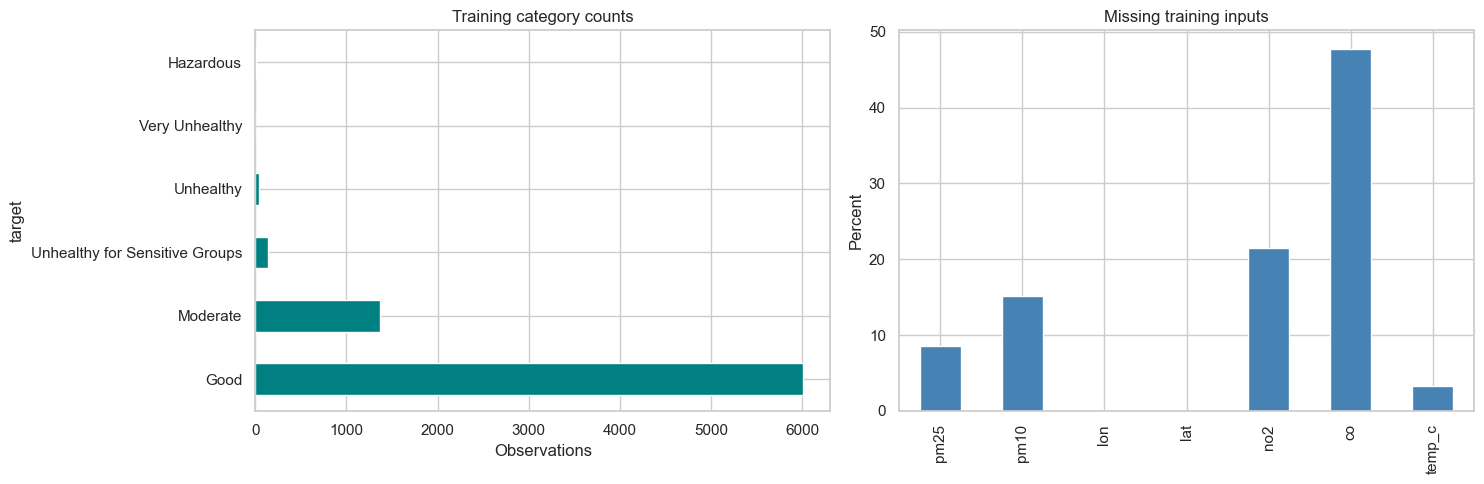

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
train["target"].value_counts().reindex(CLASSES, fill_value=0).plot.barh(ax=axes[0], color="teal")
axes[0].set_title("Training category counts")
axes[0].set_xlabel("Observations")
train[FEATURES].isna().mean().mul(100).plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("Missing training inputs")
axes[1].set_ylabel("Percent")
plt.tight_layout()
plt.show()


## 6. Training input distributions and correlations
Do not automatically remove high pollutant readings as outliers: they can represent real high-pollution events.
These correlations are descriptive and do not establish causation.


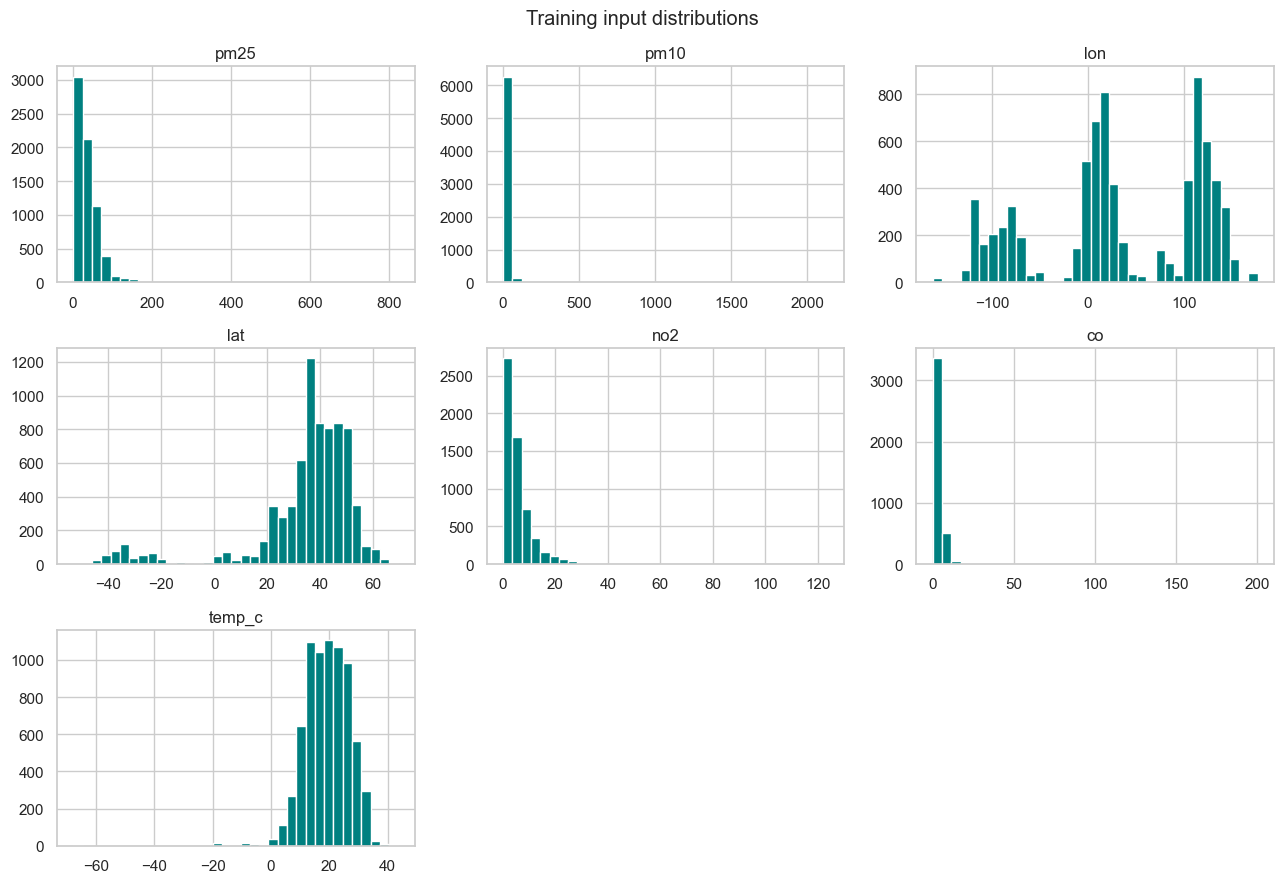

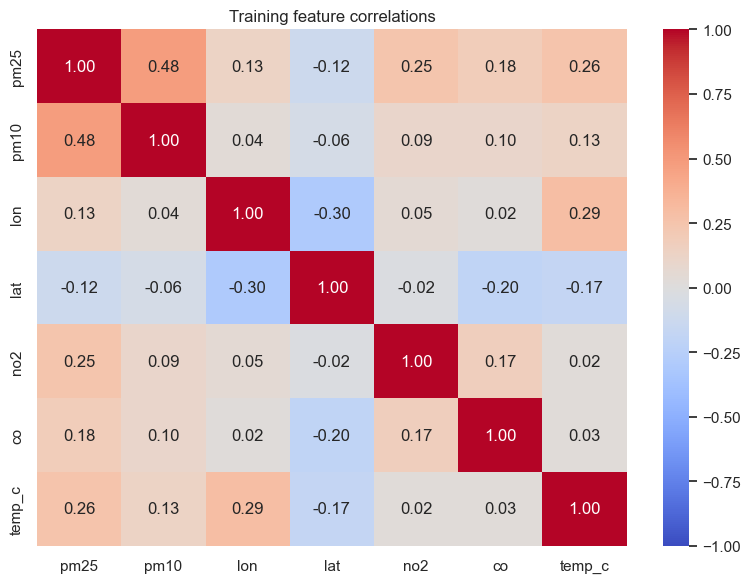

In [7]:
train[FEATURES].hist(bins=35, figsize=(13, 9), color="teal", edgecolor="white")
plt.suptitle("Training input distributions")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 6))
sns.heatmap(train[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Training feature correlations")
plt.tight_layout()
plt.show()
